<h5>Supply Chain Investigation React-agent<h5>

In [2]:
from dotenv import load_dotenv, find_dotenv
import os
load_dotenv()

True

In [3]:
import sqlite3
conn = sqlite3.connect("supply_chain.db")
cursor = conn.cursor()

In [4]:
cursor.execute("""
CREATE TABLE IF NOT EXISTS orders (
    order_id INTEGER PRIMARY KEY,
    customer_name TEXT,
    city TEXT,
    order_date TEXT
)
""")

cursor.execute("""
CREATE TABLE IF NOT EXISTS shipments (
    shipment_id INTEGER PRIMARY KEY,
    order_id INTEGER,
    courier TEXT,
    shipped_date TEXT,
    delivered_date TEXT,
    status TEXT
)
""")

orders_data = [
    (1, "Rahul", "Bangalore", "2026-04-01"),
    (2, "Anjali", "Mumbai", "2026-04-02"),
    (3, "Kiran", "Bangalore", "2026-04-03")
]

shipments_data = [
    (101, 1, "FastExpress", "2026-04-02", "2026-04-10", "Delayed"),
    (102, 2, "QuickShip", "2026-04-03", "2026-04-05", "Delivered"),
    (103, 3, "FastExpress", "2026-04-04", None, "In Transit")
]

cursor.executemany(
    "INSERT OR REPLACE INTO orders VALUES (?, ?, ?, ?)",
    orders_data
)

cursor.executemany(
    "INSERT OR REPLACE INTO shipments VALUES (?, ?, ?, ?, ?, ?)",
    shipments_data
)

conn.commit()
conn.close()

print("Database Created")

Database Created


In [5]:
openai_api_key = os.getenv("OPENAI_API_KEY")

In [13]:
# ============================================================
# STEP 2 - CONNECT SQLITE DATABASE
# ============================================================

from langchain_community.utilities import SQLDatabase

db = SQLDatabase.from_uri("sqlite:///supply_chain.db")

SQL Database Tools: The system uses tools to interact with the database schema and validate queries:

<p>DB_QUERY: Executes the generated SQL query.</p>
<p>DB_SCHEMA: Fetches the schema details of the database.</p>
<p>DB_LIST_TABLES: Lists all tables in the database.</p>
<p>DB_QUERY_CHECKER: Validates the correctness of the SQL query before execution.</p>

In [14]:
# ============================================================
# STEP 3 - Create SQL TOOls
# ============================================================
from langchain_community.agent_toolkits import SQLDatabaseToolkit
from langchain_openai import ChatOpenAI

In [15]:
llm = ChatOpenAI(temperature=0, model_name="gpt-4o-mini")

In [16]:
toolkit = SQLDatabaseToolkit(db=db, llm=llm)

In [17]:
tools = toolkit.get_tools()

In [18]:
tools

[QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x14b57ec10>),
 InfoSQLDatabaseTool(description='Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those tables. Be sure that the tables actually exist by calling sql_db_list_tables first! Example Input: table1, table2, table3', db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x14b57ec10>),
 ListSQLDatabaseTool(db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x14b57ec10>),
 QuerySQLCheckerTool(description='Use this tool to double check if your 

In [22]:
tools_by_name = {tool.name: tool for tool in tools}

In [20]:
tools_by_name

{'sql_db_query': QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x14b57ec10>),
 'sql_db_schema': InfoSQLDatabaseTool(description='Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those tables. Be sure that the tables actually exist by calling sql_db_list_tables first! Example Input: table1, table2, table3', db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x14b57ec10>),
 'sql_db_list_tables': ListSQLDatabaseTool(db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x14b57ec10>),
 'sql_db_query_ch

In [ ]:
# ============================================================
# STEP 4 - Bind Tools to LLM
# ============================================================
llm_with_tools = llm.bind_tools(tools)


In [25]:
# ============================================================
# STEP 5 - Define the Graph State
# ============================================================
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
class SupplyChainGraphState(TypedDict):
    messages: Annotated[list, add_messages]

In [27]:
# ============================================================
# STEP 6 - SYSTEM PROMPT
# ============================================================
from langchain_core.messages import SystemMessage
SYS_PRMPOT = SystemMessage(
    content = """ 
    You Are an AI supply chain investigation Agent.
    your responsibilities:
    - investigate delayed shipments
    - identify courier issues
    - analyze order problems

Rules:
1. Always inspect tables first.
2. Then inspect schema.
3. Never use INSERT, UPDATE, DELETE, DROP.
4. Use only available tools.
5. Explain findings in business language.
    """
)

In [28]:
# ============================================================
# STEP 7 - AGENT NODE
# ============================================================
def Agent_node(state:SupplyChainGraphState):
    message_to_agent = [SYS_PRMPOT] + state['messages']
    response = llm_with_tools.invoke(message_to_agent)
    
    return {
        "messages":response
    }
    

In [29]:
# ============================================================
# STEP 8 - USE BUILT-IN ToolNode
# ============================================================
from langgraph.prebuilt import ToolNode
tool_node = ToolNode(tools)

In [51]:
# ============================================================
# STEP 9 - CONDITIONAL ROUTING
# ============================================================
from langchain_core.messages import AIMessage
def should_continue(state:SupplyChainGraphState):
    last_message = state['messages'][-1]
    # If tool calls exist → go to tools node
    if isinstance(last_message,AIMessage) and last_message.tool_calls:
        return "tools"
    
    #otherwise inish
    return "end"

In [31]:
# ============================================================
# STEP 10 - BUILD GRAPH
# ============================================================

In [52]:
from langgraph.graph import StateGraph, END
graphbuilder = StateGraph(SupplyChainGraphState)

# Add node 
graphbuilder.add_node("agent", Agent_node)
graphbuilder.add_node("tools", tool_node)

# Entry point
graphbuilder.set_entry_point("agent")

# Conditional Edge
graphbuilder.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END
    }
)
# After tool execution return to agent
graphbuilder.add_edge("tools", "agent")

# graphbuilder.add_edge("tools", END)
# Compile graph
graph = graphbuilder.compile()

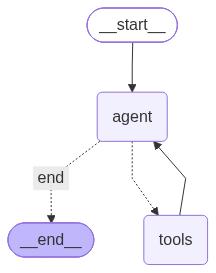

In [53]:
graph

In [54]:
from langchain_core.messages import HumanMessage
response = graph.invoke(
    {
        "messages": [
            HumanMessage(
                content="Why are orders delayed in Bangalore?"
            )
        ]
    }
)

In [55]:
response

{'messages': [HumanMessage(content='Why are orders delayed in Bangalore?', additional_kwargs={}, response_metadata={}, id='5bf4db12-d87a-4404-bfc2-49c62b30d243'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 12, 'prompt_tokens': 401, 'total_tokens': 413, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_ed36603d78', 'id': 'chatcmpl-ELnX3F5CDUF1lyr8EYYDTq3YVMNjn', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a0809a-620c-71c0-8017-ede8b3ff5ffc-0', tool_calls=[{'name': 'sql_db_list_tables', 'args': {}, 'id': 'call_pDQ0rjocfpCfUUhksrpXIWHh', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 401, 'outp

In [56]:
# ============================================================
# STEP 12 - PRINT OUTPUT
# ============================================================

print("\n================ FINAL CONVERSATION ================\n")
for message in response["messages"]:
    
    print(f"\n{message.type.upper()}")
    print("-" * 50)

    print(message.content)

    # Print tool calls if available
    if hasattr(message, "tool_calls") and message.tool_calls:
        print("\nTool Calls:")
        print(message.tool_calls)


================ FINAL CONVERSATION ================


HUMAN
--------------------------------------------------
Why are orders delayed in Bangalore?

AI
--------------------------------------------------


Tool Calls:
[{'name': 'sql_db_list_tables', 'args': {}, 'id': 'call_pDQ0rjocfpCfUUhksrpXIWHh', 'type': 'tool_call'}]

TOOL
--------------------------------------------------
orders, shipments

AI
--------------------------------------------------


Tool Calls:
[{'name': 'sql_db_schema', 'args': {'table_names': 'orders'}, 'id': 'call_ofh0HYmQi68FnJT0xbh4DWyT', 'type': 'tool_call'}, {'name': 'sql_db_schema', 'args': {'table_names': 'shipments'}, 'id': 'call_oZS0G7C3MlU2aLmisYOPL6k7', 'type': 'tool_call'}]

TOOL
--------------------------------------------------

CREATE TABLE orders (
	order_id INTEGER, 
	customer_name TEXT, 
	city TEXT, 
	order_date TEXT, 
	PRIMARY KEY (order_id)
)

/*
3 rows from orders table:
order_id	customer_name	city	order_date
1	Rahul	Bangalore	2026-04-01
2	Anja